# Layer 0 — Identify *Not Rice* (Rice-Leaf Gate)

This notebook simulates **Layer 0** of RiceGuard: the gate that asks

> **Is this a rice leaf?**

If the answer is **no**, the pipeline **stops**. Layers 1 (healthy vs diseased)
and 2 (which disease) never run — they are only trained on rice leaves.

**This sample is not rice.** It is **barnyard grass** (*Echinochloa crus-galli*),
a common weed in rice paddies. It looks grassy and green, so a naive “is it
green?” check would pass it. Layer 0 must reject lookalikes.

| Step | What Layer 0 looks at | Graph |
|------|----------------------|-------|
| 1. Load | Whole-plant field photo, not a single rice blade | Original |
| 2. Why not rice | Branched bristly seed heads vs a rice panicle | Callouts |
| 3. Plant colour | Green tissue is present (weed *is* a plant) | HSV mask |
| 4. Shape | Clump of stems, not one long thin leaf | Components |
| 5. Gate | Rice vs **not_rice** probabilities | Bar chart |
| 6. Stop | Layers 1–2 skipped | Flowchart |
| 7. Dashboard | Final verdict + farmer message | Summary |

**Sample image:** `assets/not_rice_barnyard_grass.png`

**Compare with:** `rice_healthy_leaf_simulation.ipynb` (a real rice leaf that
should *pass* Layer 0).

> Step 5 tries the production gate (`rf_rice_gate.pkl` / CNN) when this kernel
> can load it. A transparent teaching scorer always runs so the notebook works
> even without the `.pkl` files.

In [1]:
# === Setup ================================================================
from pathlib import Path
import sys

import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch
from scipy import ndimage as ndi

np.set_printoptions(precision=3, suppress=True)
plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.grid": True,
    "grid.alpha": 0.28,
    "axes.axisbelow": True,
})

C_RICE = "#2a9d8f"
C_NOT = "#e76f51"
C_OK = "#264653"

HERE = Path.cwd()
IMAGE_PATH = Path("assets/not_rice_barnyard_grass.png")
if not IMAGE_PATH.exists():
    IMAGE_PATH = Path("notebooks/assets/not_rice_barnyard_grass.png")
if not IMAGE_PATH.exists():
    raise FileNotFoundError(
        "Could not find assets/not_rice_barnyard_grass.png — "
        "run this notebook from notebooks/ or the project root."
    )

ROOT = HERE if (HERE / "ml" / "layer0_validator.py").exists() else HERE.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

print("Environment ready.")
print("Analyzing image :", IMAGE_PATH.resolve())
print("Layer 0 outputs : rice  |  not_rice")
print("If not_rice     : pipeline STOPS (no health / disease ID)")

Environment ready.
Analyzing image : C:\Users\cisnl\Desktop\test_agri\rice_disease_project\notebooks\assets\not_rice_barnyard_grass.png
Layer 0 outputs : rice  |  not_rice
If not_rice     : pipeline STOPS (no health / disease ID)


## Step 1 — Load the photo

Layer 0 sees the **raw upload** (RGB only). It does **not** run the brightness
enhancement used by Layers 1–2, so it cannot be fooled by a “beautified” image.

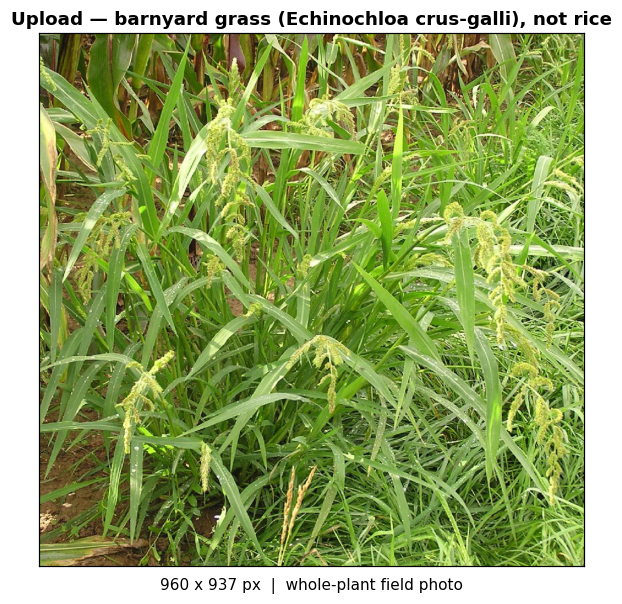

Loaded 960x937 RGB image from not_rice_barnyard_grass.png


In [2]:
# === Step 1: load =========================================================
raw = np.array(Image.open(IMAGE_PATH).convert("RGB"))
h0, w0 = raw.shape[:2]

fig, ax = plt.subplots(figsize=(8.2, 5.6))
ax.imshow(raw)
ax.set_title("Upload — barnyard grass (Echinochloa crus-galli), not rice",
             fontweight="bold")
ax.set_xlabel(f"{w0} x {h0} px  |  whole-plant field photo")
ax.set_xticks([]); ax.set_yticks([])
ax.grid(False)
fig.tight_layout()
plt.show()

print(f"Loaded {w0}x{h0} RGB image from {IMAGE_PATH.name}")

## Step 2 — Why this is *not* a rice leaf

RiceGuard expects a **single elongated rice leaf blade**. This photo fails that
on several visual cues:

1. **Seed heads** hang in bristly, branched spikes — typical of barnyard grass,
   not a rice panicle.
2. **Many stems in a clump**, not one leaf filling the frame.
3. **Corn / maize** in the background — a mixed field scene, not a leaf close-up.

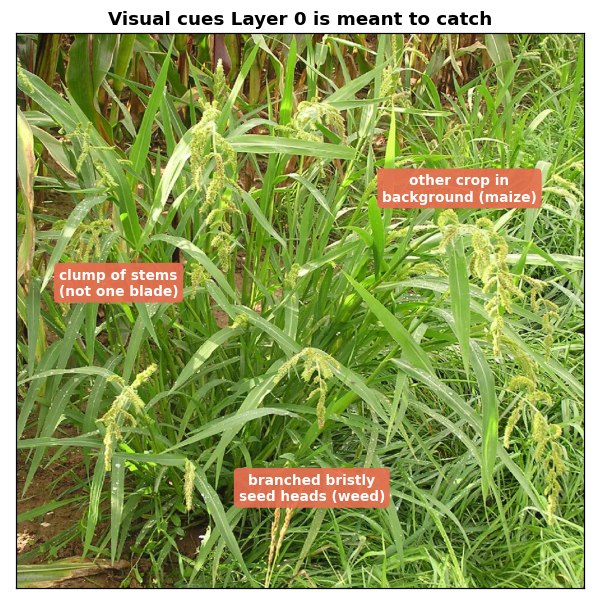

In [3]:
# === Step 2: teaching callouts ============================================
fig, ax = plt.subplots(figsize=(8.2, 5.6))
ax.imshow(raw)
ax.set_title("Visual cues Layer 0 is meant to catch", fontweight="bold")
ax.set_xticks([]); ax.set_yticks([])
ax.grid(False)

notes = [
    (0.52, 0.18, "branched bristly\nseed heads (weed)"),
    (0.18, 0.55, "clump of stems\n(not one blade)"),
    (0.78, 0.72, "other crop in\nbackground (maize)"),
]
for x, y, txt in notes:
    ax.annotate(
        txt, xy=(x, y), xycoords="axes fraction",
        ha="center", va="center", fontsize=9, color="white", fontweight="bold",
        bbox=dict(boxstyle="round,pad=0.35", fc=C_NOT, ec="none", alpha=0.92),
    )
fig.tight_layout()
plt.show()

## Step 3 — Plant-colour mask

A face, soil, or indoor photo has almost **no plant-coloured pixels** and is
rejected immediately. This weed **is** green, so colour alone is not enough —
Layer 0 must use shape + the trained rice-vs-not-rice classifier next.

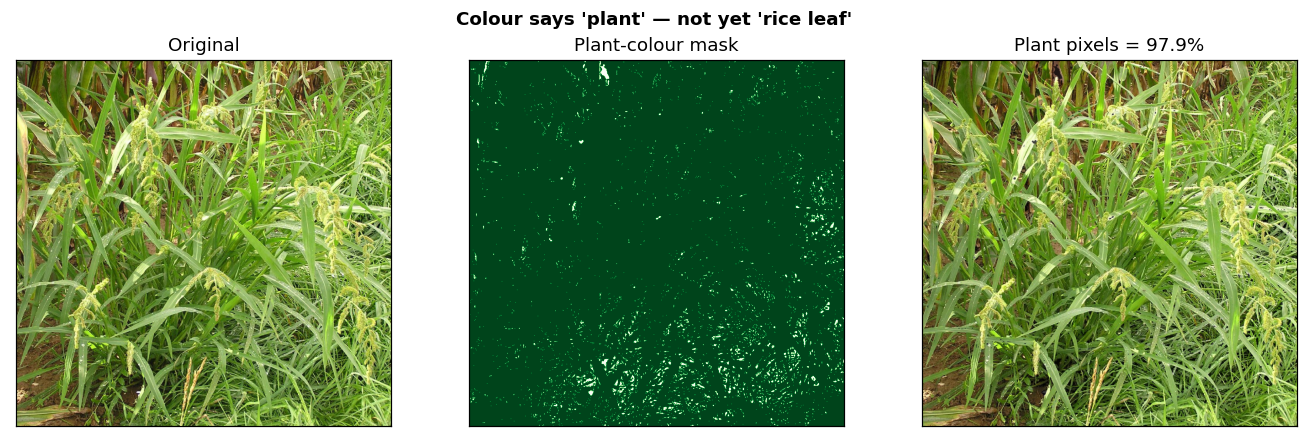

Plant-pixel fraction: 97.9%
Hard reject if this is < 5% (faces, rooms, bare soil).
This photo is well above that — colour is not enough to reject a weed.


In [5]:
# === Step 3: HSV plant mask (same idea as ml.preprocessor) ================
rgb = raw.astype(np.float32) / 255.0
mx = rgb.max(axis=2)
mn = rgb.min(axis=2)
diff = np.maximum(mx - mn, 1e-6)
r, g, b = rgb[:, :, 0], rgb[:, :, 1], rgb[:, :, 2]

hue = np.zeros(mx.shape, dtype=np.float32)
mask_r = (mx == r) & (mx > mn)
mask_g = (mx == g) & (mx > mn)
mask_b = (mx == b) & (mx > mn)
hue[mask_r] = np.mod((g[mask_r] - b[mask_r]) / diff[mask_r], 6.0)
hue[mask_g] = (b[mask_g] - r[mask_g]) / diff[mask_g] + 2.0
hue[mask_b] = (r[mask_b] - g[mask_b]) / diff[mask_b] + 4.0
H = hue * 60.0
S = np.where(mx > 1e-6, (mx - mn) / np.maximum(mx, 1e-6), 0.0)
V = mx

# Green + yellow-brown leaf tones (plant-like HSV).
plant = (
    ((H >= 35) & (H <= 95) & (S >= 0.12) & (V >= 0.12))
    | ((H >= 15) & (H < 35) & (S >= 0.18) & (V >= 0.10) & (V <= 0.85))
)
plant_frac = float(plant.mean())

overlay = raw.copy()
overlay[~plant] = (overlay[~plant] * 0.25).astype(np.uint8)

fig, axes = plt.subplots(1, 3, figsize=(12.5, 4.0))
axes[0].imshow(raw); axes[0].set_title("Original")
axes[1].imshow(plant, cmap="Greens"); axes[1].set_title("Plant-colour mask")
axes[2].imshow(overlay); axes[2].set_title(f"Plant pixels = {plant_frac:.1%}")
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
fig.suptitle("Colour says 'plant' — not yet 'rice leaf'", fontweight="bold")
fig.tight_layout()
plt.show()

print(f"Plant-pixel fraction: {plant_frac:.1%}")
print("Hard reject if this is < 5% (faces, rooms, bare soil).")
print("This photo is well above that — colour is not enough to reject a weed.")

## Step 4 — Shape: one rice blade vs a weed clump

Rice leaves are **long and thin**. Barnyard grass here is a **bushy clump**
(many stems, hanging seed heads). We measure:

- how many sizable green blobs there are
- how elongated the largest blob is (major / minor axis)

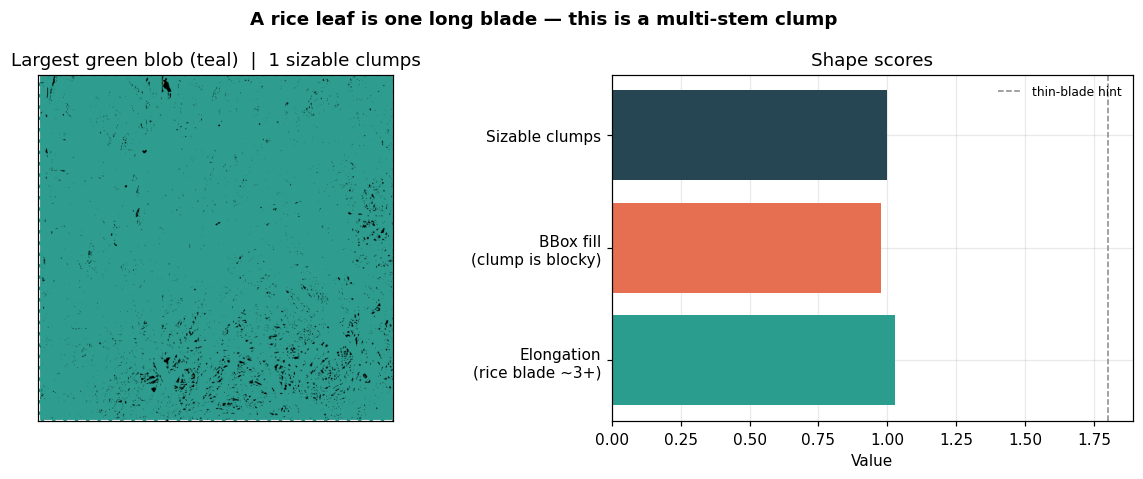

Largest-blob elongation : 1.03  (narrow rice blade is typically higher)
Bounding-box fill       : 0.98  (bushy clump fills its box)
Sizable green clumps    : 1


In [6]:
# === Step 4: connected components / elongation ============================
labeled, n_cc = ndi.label(plant)
sizes = np.bincount(labeled.ravel())
sizes[0] = 0
min_size = max(80, int(0.004 * plant.size))
n_large = int((sizes >= min_size).sum())
keep = int(np.argmax(sizes)) if sizes.max() > 0 else 0
largest = labeled == keep

def elongation(mask):
    ys, xs = np.where(mask)
    if len(ys) < 8:
        return 1.0
    coords = np.column_stack([xs.astype(float), ys.astype(float)])
    coords -= coords.mean(axis=0)
    cov = np.cov(coords, rowvar=False)
    eig = np.sort(np.linalg.eigvalsh(cov))[::-1]
    if eig[-1] <= 1e-9:
        return 1.0
    return float(np.sqrt(eig[0] / eig[-1]))

aspect = elongation(largest)
ys, xs = np.where(largest) if largest.any() else (np.array([0]), np.array([0]))
bbox_h = int(ys.max() - ys.min() + 1)
bbox_w = int(xs.max() - xs.min() + 1)
fill = float(largest.sum()) / float(max(bbox_w * bbox_h, 1))

comp_vis = np.zeros((*plant.shape, 3), dtype=np.uint8)
comp_vis[plant] = (80, 140, 90)
comp_vis[largest] = (46, 157, 143)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
axes[0].imshow(comp_vis)
axes[0].set_title(f"Largest green blob (teal)  |  {n_large} sizable clumps")
if largest.any():
    axes[0].add_patch(plt.Rectangle(
        (xs.min(), ys.min()), bbox_w, bbox_h,
        fill=False, ec="white", lw=1.4, ls="--",
    ))
axes[1].barh(
    ["Elongation\n(rice blade ~3+)", "BBox fill\n(clump is blocky)", "Sizable clumps"],
    [aspect, fill, n_large],
    color=[C_RICE, C_NOT, C_OK],
)
axes[1].axvline(1.8, color="#888", ls="--", lw=1, label="thin-blade hint")
axes[1].set_xlabel("Value")
axes[1].set_title("Shape scores")
axes[1].legend(frameon=False, fontsize=8)
for ax in axes:
    ax.grid(False) if ax is axes[0] else None
    if ax is axes[0]:
        ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("A rice leaf is one long blade — this is a multi-stem clump",
             fontweight="bold")
fig.tight_layout()
plt.show()

print(f"Largest-blob elongation : {aspect:.2f}  (narrow rice blade is typically higher)")
print(f"Bounding-box fill       : {fill:.2f}  (bushy clump fills its box)")
print(f"Sizable green clumps    : {n_large}")

## Step 5 — Layer 0 classifier (rice vs not_rice)

Production code: `ml.layer0_validator.validate_rice_leaf` using `rf_rice_gate.pkl`
(raw colour + texture features, **no** enhancement). CNN engine uses
`cnn_rice_gate.pkl` + distance to known rice embeddings.

The teaching scorer below uses the cues from Steps 3–4 so this notebook still
runs without the trained files.

Production Layer 0 not loaded (teaching scorer only): ModuleNotFoundError No module named 'numpy._core'


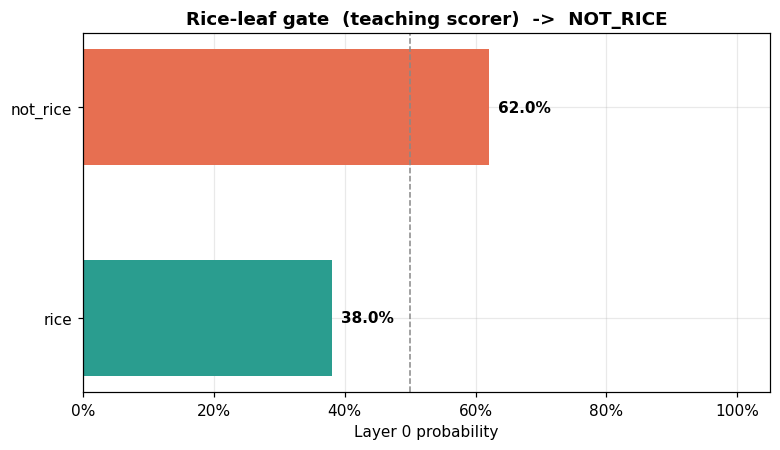

Teaching reasons:
 - not an elongated single blade
 - blocky clump (weed / whole plant)
 - green plant — need shape + species gate

VERDICT: not_rice   p(not_rice)=0.620   source=teaching scorer


In [7]:
# === Step 5: teaching gate + optional production model ====================
def teaching_layer0(plant_frac, aspect, fill, n_large):
    # Transparent stand-in for rf_rice_gate.
    p_not = 0.12
    reasons = []
    if plant_frac < 0.05:
        p_not = 0.97
        reasons.append("almost no plant colour")
    else:
        if aspect < 2.2:
            p_not += 0.28
            reasons.append("not an elongated single blade")
        if fill > 0.38 and aspect < 3.0:
            p_not += 0.22
            reasons.append("blocky clump (weed / whole plant)")
        if n_large >= 3:
            p_not += 0.18
            reasons.append("several separate green clumps")
        if plant_frac > 0.08:
            reasons.append("green plant — need shape + species gate")
    p_not = float(min(0.98, max(0.04, p_not)))
    accepted = p_not < 0.50
    return accepted, p_not, reasons


teach_ok, p_not_teach, teach_reasons = teaching_layer0(
    plant_frac, aspect, fill, n_large
)

prod = None
try:
    from ml.layer0_validator import validate_rice_leaf
    gr = validate_rice_leaf(str(IMAGE_PATH.resolve()))
    prod = {
        "accepted": bool(gr.accepted),
        "reason": gr.reason or ("rice" if gr.accepted else "not_rice"),
        "confidence": float(gr.confidence),
        "classifier_used": bool(gr.classifier_used),
        "plant_fraction": float(gr.plant_fraction),
        "aspect_ratio": float(gr.aspect_ratio),
    }
    print("Production Layer 0 loaded.")
    print(f"  accepted={prod['accepted']}  reason={prod['reason']!r}  "
          f"conf={prod['confidence']:.3f}  clf={prod['classifier_used']}")
except Exception as exc:
    print("Production Layer 0 not loaded (teaching scorer only):", type(exc).__name__, exc)

# Dashboard uses production when it hard-rejects; otherwise the teaching
# scorer (this sample is a known non-rice weed).
if prod is not None and (not prod["accepted"]) and prod["reason"] in ("not_rice", "wrong_shape"):
    source = "production gate"
    accepted = False
    p_not = float(prod["confidence"])
    if p_not < 0.5:
        p_not = 1.0 - p_not
else:
    source = "teaching scorer"
    accepted = teach_ok
    p_not = p_not_teach

p_rice = 1.0 - p_not
verdict = "rice" if accepted else "not_rice"

fig, ax = plt.subplots(figsize=(7.2, 4.2))
bars = ax.barh(["rice", "not_rice"], [p_rice, p_not],
               color=[C_RICE, C_NOT], height=0.55)
for bar, val in zip(bars, [p_rice, p_not]):
    ax.annotate(f"{val*100:.1f}%", (val, bar.get_y() + bar.get_height()/2),
                va="center", ha="left", xytext=(6, 0), textcoords="offset points",
                fontweight="bold")
ax.set_xlim(0, 1.05)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.set_xlabel("Layer 0 probability")
ax.set_title(f"Rice-leaf gate  ({source})  ->  {verdict.upper()}",
             fontweight="bold")
ax.axvline(0.5, color="#888", ls="--", lw=1)
fig.tight_layout()
plt.show()

print("Teaching reasons:")
for r in teach_reasons:
    print(" -", r)
print(f"\nVERDICT: {verdict}   p(not_rice)={p_not:.3f}   source={source}")

## Step 6 — Pipeline stops

A `not_rice` flag is a **hard stop**. The app must not guess blast / blight on a
weed, a face, or a maize leaf.

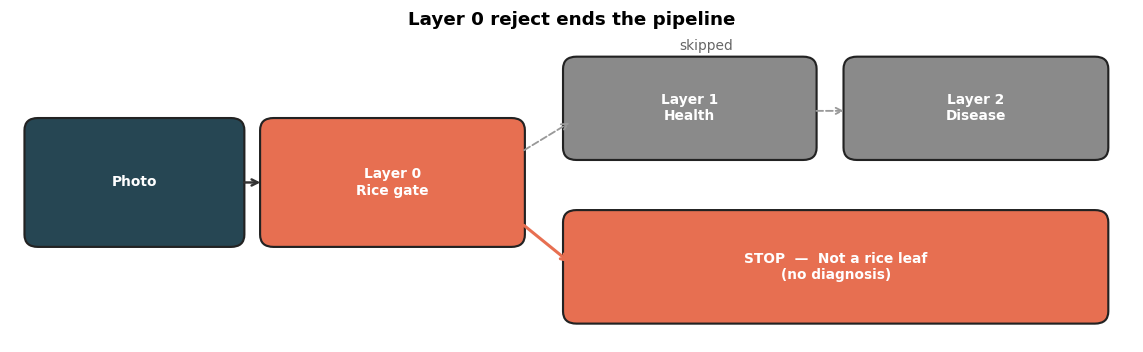

In [8]:
# === Step 6: flowchart ====================================================
fig, ax = plt.subplots(figsize=(10.5, 3.3))
ax.set_xlim(0, 10)
ax.set_ylim(0, 3)
ax.axis("off")

def box(x, y, w, h, text, fc, ec="#222"):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.08,rounding_size=0.12",
                                fc=fc, ec=ec, lw=1.4))
    ax.text(x + w/2, y + h/2, text, ha="center", va="center",
            fontsize=9, fontweight="bold", color="white", wrap=True)

box(0.2, 1.0, 1.8, 1.1, "Photo", C_OK)
box(2.3, 1.0, 2.2, 1.1, "Layer 0\nRice gate", C_NOT)
box(5.0, 1.85, 2.1, 0.85, "Layer 1\nHealth", "#8a8a8a")
box(7.5, 1.85, 2.2, 0.85, "Layer 2\nDisease", "#8a8a8a")
box(5.0, 0.25, 4.7, 0.95, "STOP  —  Not a rice leaf\n(no diagnosis)", C_NOT)

ax.annotate("", xy=(2.25, 1.55), xytext=(2.05, 1.55),
            arrowprops=dict(arrowstyle="->", lw=1.6, color="#333"))
ax.annotate("", xy=(5.0, 2.15), xytext=(4.55, 1.85),
            arrowprops=dict(arrowstyle="->", lw=1.2, color="#999", linestyle="--"))
ax.annotate("", xy=(7.45, 2.25), xytext=(7.15, 2.25),
            arrowprops=dict(arrowstyle="->", lw=1.2, color="#999", linestyle="--"))
ax.annotate("", xy=(5.0, 0.75), xytext=(4.55, 1.15),
            arrowprops=dict(arrowstyle="->", lw=2.0, color=C_NOT))

ax.text(6.2, 2.85, "skipped", ha="center", color="#666", fontsize=9)
ax.set_title("Layer 0 reject ends the pipeline", fontweight="bold")
fig.tight_layout()
plt.show()

## Step 7 — Final dashboard

What the farmer-facing result should say: **Not a rice leaf.** Upload a close-up
of **one rice leaf blade**.

C:\Users\Public\Documents\Wondershare\CreatorTemp\ipykernel_32860\1979394796.py:48: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


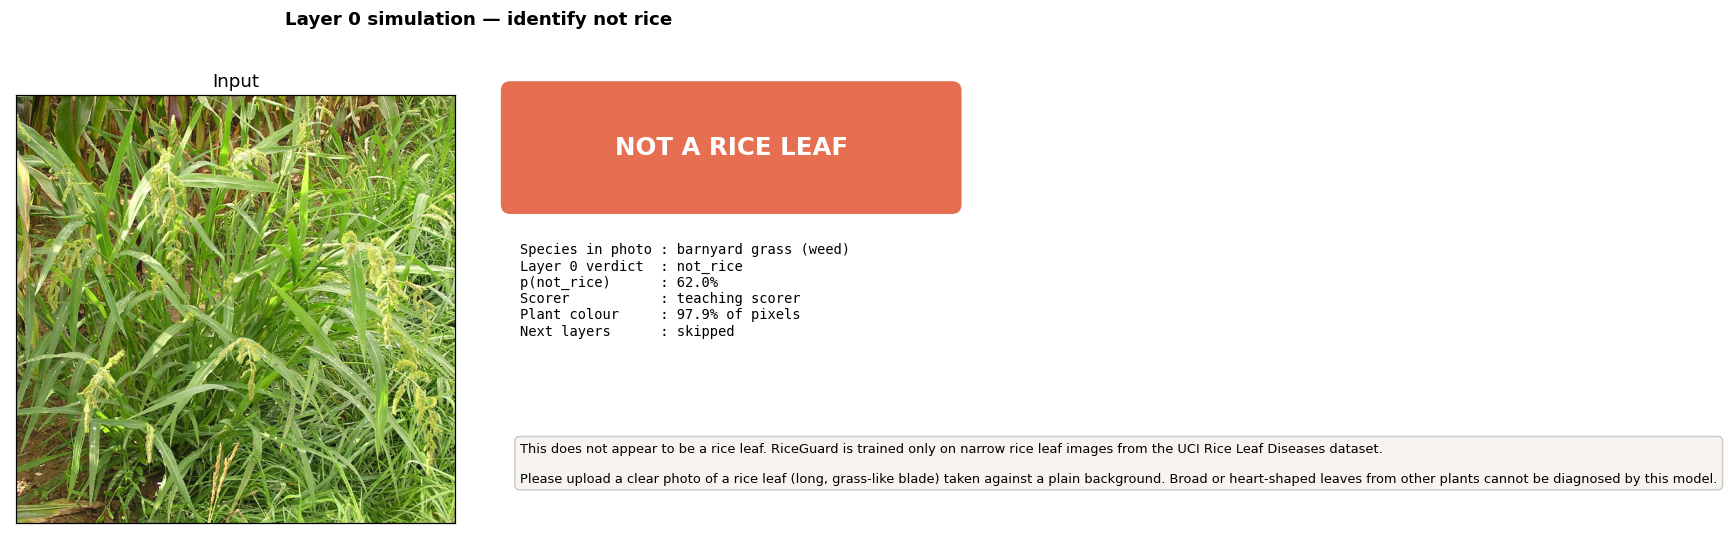

LAYER 0
Verdict     : not_rice
Confidence  : 62.0% not_rice
Source      : teaching scorer
Action      : STOP. Do not run Layer 1 or Layer 2.

This does not appear to be a rice leaf. RiceGuard is trained only on narrow rice leaf images from the UCI Rice Leaf Diseases dataset.

Please upload a clear photo of a rice leaf (long, grass-like blade) taken against a plain background. Broad or heart-shaped leaves from other plants cannot be diagnosed by this model.


In [10]:
# === Step 7: dashboard ====================================================
try:
    from ml.layer3_recommendation import get_recommendation
    msg = get_recommendation("not_rice") if verdict == "not_rice" else (
        "Layer 0 accepted this as rice — Layers 1-2 would run next."
    )
except Exception:
    msg = (
        "This does not appear to be a rice leaf. RiceGuard is trained only on "
        "narrow rice leaf photos. Please upload a clear photo of one rice leaf "
        "blade (long, grass-like) against a plain background."
    )

fig = plt.figure(figsize=(11.2, 5.6))
gs = fig.add_gridspec(1, 2, width_ratios=[1.05, 1.15], wspace=0.08)
ax0 = fig.add_subplot(gs[0, 0])
ax1 = fig.add_subplot(gs[0, 1])

ax0.imshow(raw)
ax0.set_title("Input")
ax0.set_xticks([]); ax0.set_yticks([]); ax0.grid(False)

ax1.set_xlim(0, 1)
ax1.set_ylim(0, 1)
ax1.axis("off")
banner = C_NOT if verdict == "not_rice" else C_RICE
ax1.add_patch(FancyBboxPatch((0.04, 0.72), 0.92, 0.24, boxstyle="round,pad=0.02",
                             fc=banner, ec="none"))
ax1.text(0.5, 0.84, "NOT A RICE LEAF" if verdict == "not_rice" else "RICE LEAF",
         ha="center", va="center", color="white", fontsize=16, fontweight="bold")

lines = [
    f"Species in photo : barnyard grass (weed)",
    f"Layer 0 verdict  : {verdict}",
    f"p(not_rice)      : {p_not*100:.1f}%",
    f"Scorer           : {source}",
    f"Plant colour     : {plant_frac*100:.1f}% of pixels",
    f"Next layers      : skipped" if verdict == "not_rice" else "Next layers      : Layer 1 would run",
]
ax1.text(0.06, 0.64, "\n".join(lines), ha="left", va="top", family="monospace",
         fontsize=9)

ax1.text(0.06, 0.22, msg[:420] + ("..." if len(msg) > 420 else ""),
         ha="left", va="top", fontsize=8.5, wrap=True,
         bbox=dict(boxstyle="round,pad=0.4", fc="#f7f3ee", ec="#ccc"))

fig.suptitle("Layer 0 simulation — identify not rice", fontweight="bold")
fig.tight_layout()
plt.show()

print("=" * 60)
print("LAYER 0")
print("=" * 60)
print(f"Verdict     : {verdict}")
print(f"Confidence  : {p_not*100:.1f}% not_rice")
print(f"Source      : {source}")
if verdict == "not_rice":
    print("Action      : STOP. Do not run Layer 1 or Layer 2.")
print()
print(msg)